# Partial observations: deploying an echo state network when a component is never measured

The sensors measure $x$ and $z$ of the Lorenz-63 system; $y$ is never measured. Two networks, both with the full state as output (`scripts/esnda/configs/lorenz63.yml`):

- **partial-input:** the inputs are the measured components; it can be deployed with a washout, the substitution of the data, or the filter;
- **full-input:** the inputs are the full state, as in tutorial 40; only the filter can deploy it, because $y$ is not available.

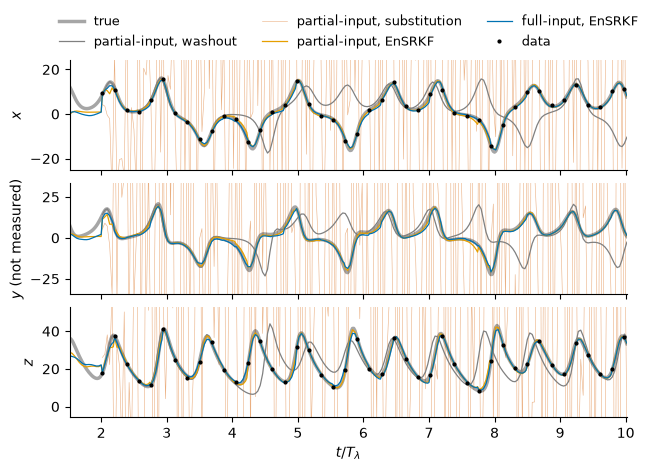

In [1]:
import numpy as np

from romda.models.physical import Lorenz63
from romda.models.data_driven.rnns import model_esn
from romda.observations import Observations
from romda.data_assimilation import deploy
from romda.metrics import valid_time
from romda.run import innovation_options
from romda.utils import interpolate
from aux_4X import BLUE, GREY, ORANGE, VERMILLION, config, plot_components, plot_dot_rows

CONFIG = config('lorenz63')
DA = CONFIG['da']
MEASURED, HIDDEN = [0, 2], [1]

esn_full, data = model_esn(Lorenz63, CONFIG['truth'], CONFIG['forecast']['esn'])
esn_partial, _ = model_esn(Lorenz63, CONFIG['truth'], CONFIG['forecast']['esn'], measured=MEASURED, bayesian_update=False)
t_lyap, i_test = data['t_lyap'], data['i_test']
clean, noisy = data['clean_data'][i_test:], data['noisy_data'][i_test:]
t = data['t'][i_test:] - data['t'][i_test]
sigma = clean.std(axis=0)
T_START, T_STOP, T_FORECAST = CONFIG['window_lyap']
FILTER = dict(m=DA['m'], da_method=DA['da_method'], cdd_fraction=DA['cdd_fraction'],
              inflation=DA['inflation'], **innovation_options(DA), t_extra=T_FORECAST * t_lyap)


def observe(measured=MEASURED, window=0):
    """Noisy observations of `measured` every 0.19 Lyapunov times, for 20 Lyapunov times."""
    return Observations(y_raw=noisy[:, measured], y_true=clean[:, measured], t_true=t, Nt_obs=DA['Nt_obs'],
                        t_start=(T_START + 4 * window) * t_lyap, t_stop=(T_STOP + 4 * window) * t_lyap)


def errors(run, truth):
    """Error of each component (normalized by its standard deviation), and its root mean square after two Lyapunov
    times of data, over the three components and over y."""
    e = (run['y'] - interpolate(t, clean, run['t'])) / sigma
    w = (run['t'] >= truth.t_obs[0] + 2 * t_lyap) & (run['t'] <= truth.t_obs[-1])
    return e, np.sqrt(np.mean(e[w] ** 2)), np.sqrt(np.mean(e[w][:, HIDDEN] ** 2))


def washout_forecast(truth):
    """Partial-input network: washout on the measured components at every network step, then closed loop."""
    i0 = int(np.searchsorted(t, truth.t_obs[0]))
    n = int((truth.t_obs[-1] + T_FORECAST * t_lyap - truth.t_obs[0]) / esn_partial.dt_ESN)
    y, _ = esn_partial.closed_loop(noisy[i0 - esn_partial.N_wash * esn_partial.upsample::esn_partial.upsample], n)
    return dict(t=t[i0] + np.arange(n) * esn_partial.dt_ESN, y=y, ensemble=None)


def deployments(truth):
    return {'partial-input, washout': (washout_forecast(truth), GREY),
            'partial-input, substitution': (deploy(esn_partial, truth, measured=MEASURED, bayesian_update=False,
                                                   open_loop_ensemble=True, m=DA['m'], t_extra=T_FORECAST * t_lyap),
                                            VERMILLION),
            'partial-input, EnSRKF': (deploy(esn_partial, truth, **FILTER), ORANGE),
            'full-input, EnSRKF': (deploy(esn_full, truth, measured=MEASURED, **FILTER), BLUE)}


truth = observe()
runs = deployments(truth)
plot_components(runs, truth, t, clean, t_lyap, MEASURED)

Ten windows:

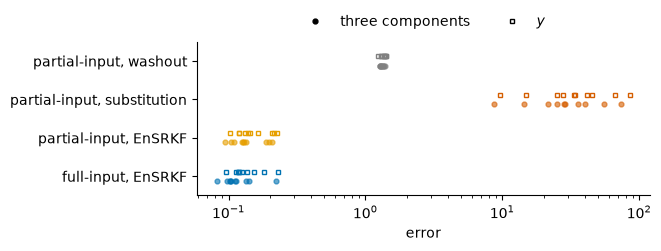

partial-input, washout         median error 1.308, of y 1.356
partial-input, substitution    median error 28.392, of y 33.431
partial-input, EnSRKF          median error 0.128, of y 0.141
full-input, EnSRKF             median error 0.107, of y 0.123
valid time of the washout forecast: median 2.0 Lyapunov times


In [2]:
table = np.array([[errors(run, truth_w)[1:] for run, _ in deployments(truth_w).values()]
                  for truth_w in (observe(window=w) for w in range(10))]).transpose(1, 0, 2)
plot_dot_rows(table, list(runs), [c for _, c in runs.values()])
for label, row in zip(runs, np.median(table, axis=1)):
    print(f'{label:<30} median error {row[0]:.3f}, of y {row[1]:.3f}')
vt = [valid_time(np.sqrt(np.mean(errors(r, tr)[0] ** 2, axis=1)), r['t'] - r['t'][0]) / t_lyap
      for tr in (observe(window=w) for w in range(10)) for r in [washout_forecast(tr)]]
print(f'valid time of the washout forecast: median {np.median(vt):.1f} Lyapunov times')

- The washout forecast is valid for about two Lyapunov times and then loses the state, because it gets no more data.
- The substitution fails: correcting the input alone does not synchronize the reservoir.
- Only the filters estimate the state, $y$ included, from the sparse data. The full-input network has the lower error, and one network serves every sensor layout.

## Which components must be measured?

In [3]:
for measured in ([0, 2], [0], [1], [2]):
    e = [errors(deploy(esn_full, tr, measured=measured, **FILTER), tr)[1] for tr in (observe(measured, w) for w in range(10))]
    print(f'{", ".join("xyz"[k] for k in measured):<6} median error {np.median(e):.3f}, failed windows {np.sum(np.array(e) > 1)}')

x, z   median error 0.107, failed windows 0


x      median error 0.158, failed windows 0


y      median error 0.104, failed windows 0


z      median error 307.414, failed windows 9


$x$ alone or $y$ alone suffice; $z$ alone does not. The Lorenz-63 system is invariant under $(x, y, z) \to (-x, -y, z)$, so $z$ does not determine the sign of $x$ and $y$, and the posterior is bimodal. Tutorial 17 introduces the Gaussian-mixture filter for this case.